In [18]:
import numpy as np
import pandas as pd

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

from pathlib import Path
from rasterio.enums import Resampling
from rasterio.windows import Window

%matplotlib inline

plt.rcParams.update({
    "font.size": 12,
    "figure.dpi": 120,
    "axes.grid": False
})

print("Rasterio:", rasterio.__version__)
print("Libraries imported successfully.")

Rasterio: 1.5.2
Libraries imported successfully.


# Define the project directories

In [20]:
# Locate project directory

ROOT = Path.cwd().resolve()

if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
NOTEBOOK_DIR = ROOT / "notebooks"

print("Project root:", ROOT)
print("Data directory:", DATA_DIR)
print("Data directory exists:", DATA_DIR.exists())

Project root: /Users/sourabh/Documents/python_codes/venus_clus
Data directory: /Users/sourabh/Documents/python_codes/venus_clus/data
Data directory exists: True


In [21]:
FILES = {
    "Emissivity": DATA_DIR / "Venus_Magellan_MicrowaveEmissivity_Global_4641m.tif",

    "Reflectivity": DATA_DIR / "Venus_Magellan_FresnelReflectivity_Global_4641m.tif",

    "RMS_Slope": DATA_DIR / "Venus_Magellan_MeterScaleSlope_Global_4641m.tif",

    "Topography": DATA_DIR / "Venus_Magellan_Topography_Global_4641m_v02.tif",

    "SAR": DATA_DIR / "Venus_Magellan_C3-MDIR_Global_Mosaic_2025m.tif"
}

for name, path in FILES.items():
    print(f"{name:15s} | Exists: {path.exists()}")

missing = [name for name, path in FILES.items() if not path.exists()]

if missing:
    raise FileNotFoundError(f"Missing datasets: {missing}")

Emissivity      | Exists: True
Reflectivity    | Exists: True
RMS_Slope       | Exists: True
Topography      | Exists: True
SAR             | Exists: True


## Original Raster Metadata

In [22]:
metadata = []

for name, path in FILES.items():

    with rasterio.open(path) as src:

        metadata.append({
            "Dataset": name,
            "Width": src.width,
            "Height": src.height,
            "Bands": src.count,
            "Data_Type": src.dtypes[0],
            "Resolution_X": src.res[0],
            "Resolution_Y": src.res[1],
            "NoData": src.nodata,
            "CRS": str(src.crs)
        })

df_metadata = pd.DataFrame(metadata)

display(df_metadata)

# Inspect map bounds and coordinate systems
for name, path in FILES.items():

    with rasterio.open(path) as src:

        print("\n", "=" * 60)
        print(name)
        print("CRS:", src.crs)
        print("Bounds:", src.bounds)
        print("Transform:", src.transform)
        print("Scale:", src.scales)
        print("Offset:", src.offsets)

,Dataset,Width,Height,Bands,Data_Type,Resolution_X,Resolution_Y,NoData,CRS
0,Emissivity,8193,4097,1,int16,4641.0588,4641.0588,-32768.0,"PROJCS[""SimpleCylindrical Venus"",GEOGCS[""GCS_V..."
1,Reflectivity,8193,4097,1,uint8,4641.0588,4641.0588,0.0,"PROJCS[""SimpleCylindrical Venus"",GEOGCS[""GCS_V..."
2,RMS_Slope,8193,4097,1,uint8,4641.0588,4641.0588,0.0,"PROJCS[""SimpleCylindrical Venus"",GEOGCS[""GCS_V..."
3,Topography,8192,4096,1,int16,4641.0589,4641.0589,-32768.0,"PROJCS[""SimpleCylindrical Venus"",GEOGCS[""GCS_V..."
4,SAR,18775,9388,1,uint8,2025.0000,2025.0000,0.0,"PROJCS[""Equirectangular Venus"",GEOGCS[""GCS_Ven..."



Emissivity
CRS: PROJCS["SimpleCylindrical Venus",GEOGCS["GCS_Venus",DATUM["D_Venus",SPHEROID["Venus",6051000,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Bounds: BoundingBox(left=-19014417.9036, bottom=-9504888.4224, right=19009776.844799995, top=9509529.4812)
Transform: | 4641.06, 0.00,-19014417.90|
| 0.00,-4641.06, 9509529.48|
| 0.00, 0.00, 1.00|
Scale: (0.0001,)
Offset: (-0.000100000000000211,)

Reflectivity
CRS: PROJCS["SimpleCylindrical Venus",GEOGCS["GCS_Venus",DATUM["D_Venus",SPHEROID["Venus",6051000,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PA

# Create a function to read and decode the datasets

In [23]:
def read_magellan(name, window=None, out_shape=None):

    path = FILES[name]

    with rasterio.open(path) as src:

        kwargs = {"masked": True}

        if window is not None:
            kwargs["window"] = window

        if out_shape is not None:
            kwargs["out_shape"] = out_shape
            kwargs["resampling"] = Resampling.nearest

        # Read stored pixel values
        raw = src.read(1, **kwargs).astype(np.float32)

        # Handle invalid values
        raw = np.ma.masked_invalid(raw)

        if name in ["Emissivity", "Reflectivity", "RMS_Slope"]:
            raw = np.ma.masked_where(raw == 0, raw)

        if name == "Topography":
            raw = np.ma.masked_where(raw == -32768, raw)

        # Apply GeoTIFF scaling information
        scale = src.scales[0]
        offset = src.offsets[0]

        data = raw * scale + offset

        return np.ma.masked_invalid(data)

In [33]:
# Check physical values after scale/offset correction

summary = []

for name in FILES:

    data = read_magellan(
        name,
        out_shape=(500, 1000)
    )

    values = data.compressed()

    summary.append({
        "Dataset": name,
        "Minimum": np.min(values),
        "P01": np.percentile(values, 1),
        "Median": np.median(values),
        "Mean": np.mean(values),
        "P99": np.percentile(values, 99),
        "Maximum": np.max(values)
    })

df_summary = pd.DataFrame(summary)

display(df_summary.round(4))

,Dataset,Minimum,P01,Median,Mean,P99,Maximum
0,Emissivity,0.3136,0.6997,0.8517,0.8478,0.9059,0.9922
1,Reflectivity,0.0050,0.0600,0.1200,0.1406,0.3750,0.9650
2,RMS_Slope,-0.0850,-0.0550,0.0350,0.0501,0.3300,0.5300
3,Topography,-2665.0000,-692.0000,604.0000,819.0982,4530.0000,11213.0000
4,SAR,1.0000,87.0000,128.0000,129.4172,188.0000,240.0000


In [34]:
df_summary.to_csv("df_summary.csv")

In [35]:
# Check the original RMS slope encoding

with rasterio.open(FILES["RMS_Slope"]) as src:

    raw = src.read(
        1,
        out_shape=(500, 1000),
        resampling=Resampling.nearest,
        masked=True
    )

    raw_values = raw.compressed()
    raw_values = raw_values[raw_values != 0]

    print("Data type:", src.dtypes[0])
    print("GeoTIFF scale:", src.scales[0])
    print("GeoTIFF offset:", src.offsets[0])

    print("\nRaw pixel value statistics:")
    print("Minimum:", np.min(raw_values))
    print("Median:", np.median(raw_values))
    print("Maximum:", np.max(raw_values))

    print("\nPDS slope decoding (degrees):")

    slope_pds = (raw_values.astype(float) - 1) / 10

    print("Minimum:", np.min(slope_pds))
    print("Median:", np.median(slope_pds))
    print("Mean:", np.mean(slope_pds))
    print("Maximum:", np.max(slope_pds))

    print("\nUnique raw values (first 30):")
    print(np.unique(raw_values)[:30])

Data type: uint8
GeoTIFF scale: 0.005
GeoTIFF offset: -0.1

Raw pixel value statistics:
Minimum: 3
Median: 27.0
Maximum: 126

PDS slope decoding (degrees):
Minimum: 0.2
Median: 2.6
Mean: 2.9013446621648162
Maximum: 12.5

Unique raw values (first 30):
[ 3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26
 27 28 29 30 31 32]


## Examine numerical distribution

In [24]:
summary = []

for name, path in FILES.items():

    with rasterio.open(path) as src:

        sample_shape = (
            min(500, src.height),
            min(1000, src.width)
        )

    data = read_magellan(
        name,
        out_shape=sample_shape
    )

    values = data.compressed()

    summary.append({
        "Dataset": name,
        "Minimum": np.min(values),
        "P01": np.percentile(values, 1),
        "Median": np.median(values),
        "Mean": np.mean(values),
        "P99": np.percentile(values, 99),
        "Maximum": np.max(values),
        "Valid_Pixels": len(values)
    })

df_summary = pd.DataFrame(summary)

display(df_summary.round(4))

,Dataset,Minimum,P01,Median,Mean,P99,Maximum,Valid_Pixels
0,Emissivity,0.3136,0.6997,0.8517,0.8478,0.9059,0.9922,480427
1,Reflectivity,0.0050,0.0600,0.1200,0.1406,0.3750,0.9650,436575
2,RMS_Slope,-0.0850,-0.0550,0.0350,0.0501,0.3300,0.5300,458182
3,Topography,-2665.0000,-692.0000,604.0000,819.0982,4530.0000,11213.0000,458469
4,SAR,1.0000,87.0000,128.0000,129.4172,188.0000,240.0000,459449


## Create a five-panel global map

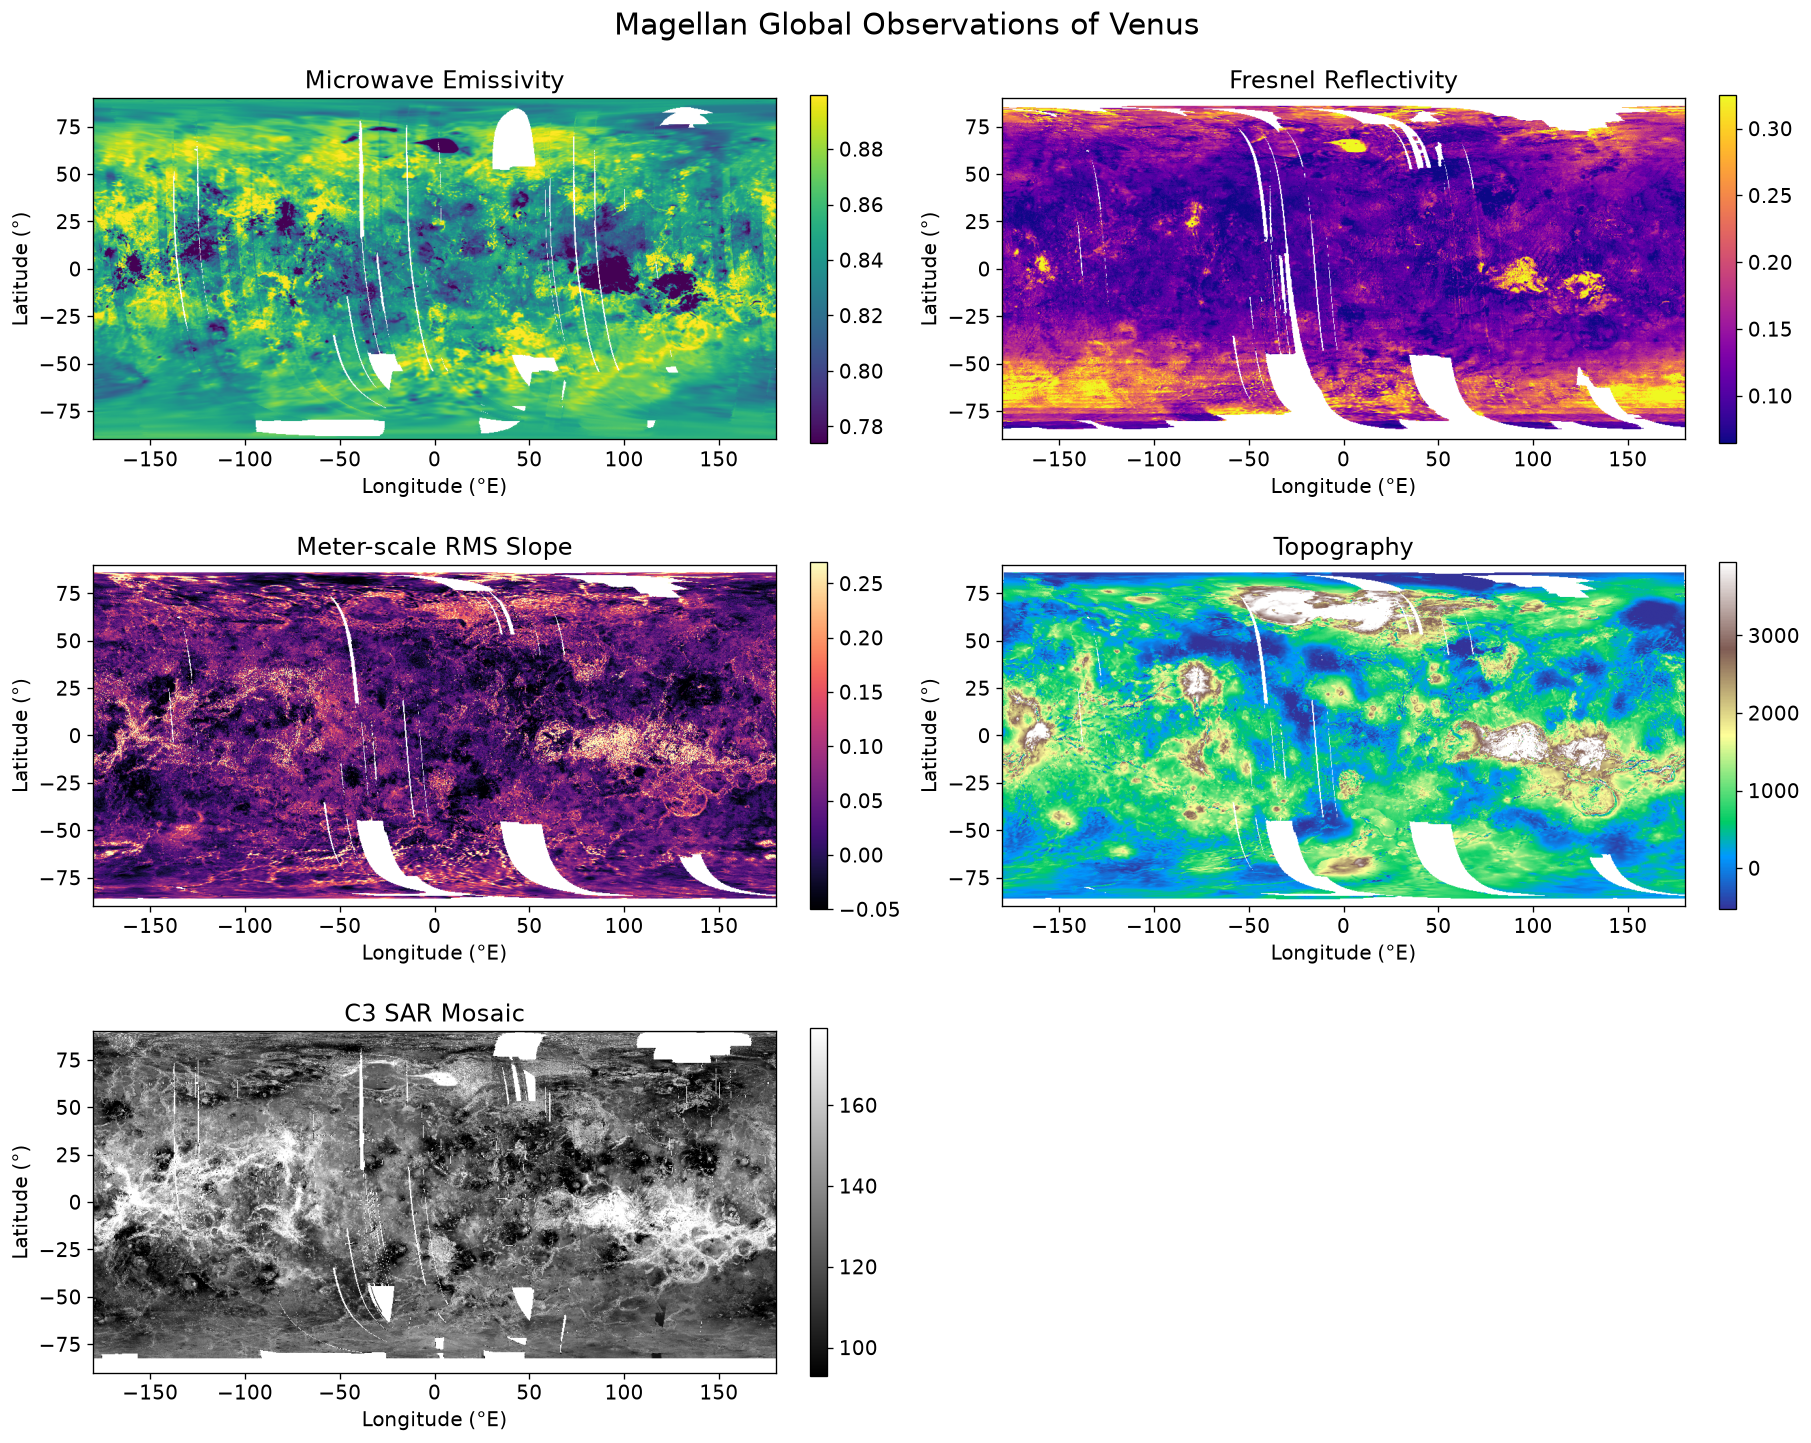

In [25]:
datasets = [
    "Emissivity",
    "Reflectivity",
    "RMS_Slope",
    "Topography",
    "SAR"
]

titles = {
    "Emissivity": "Microwave Emissivity",
    "Reflectivity": "Fresnel Reflectivity",
    "RMS_Slope": "Meter-scale RMS Slope",
    "Topography": "Topography",
    "SAR": "C3 SAR Mosaic"
}

cmaps = {
    "Emissivity": "viridis",
    "Reflectivity": "plasma",
    "RMS_Slope": "magma",
    "Topography": "terrain",
    "SAR": "gray"
}

fig, axes = plt.subplots(
    3, 2,
    figsize=(15, 12),
    constrained_layout=True
)

axes = axes.flatten()

for i, name in enumerate(datasets):

    data = read_magellan(
        name,
        out_shape=(500, 1000)
    )

    values = data.compressed()

    vmin, vmax = np.percentile(values, [2, 98])

    im = axes[i].imshow(
        data,
        cmap=cmaps[name],
        vmin=vmin,
        vmax=vmax,
        origin="upper",
        extent=[-180, 180, -90, 90]
    )

    axes[i].set_title(titles[name])
    axes[i].set_xlabel("Longitude (°E)")
    axes[i].set_ylabel("Latitude (°)")

    plt.colorbar(
        im,
        ax=axes[i],
        shrink=0.8
    )

axes[-1].axis("off")

plt.suptitle(
    "Magellan Global Observations of Venus",
    fontsize=18
)

plt.show()

# Extract Alpha Regio and Themis Regio

## Define study regions

In [26]:
REGIONS = {

    "Alpha_Regio": {
        "lon_min": -10,
        "lon_max": 20,
        "lat_min": -35,
        "lat_max": -15
    },

    "Themis_Regio": {
        "lon_min": -90,
        "lon_max": -72,
        "lat_min": -47,
        "lat_max": -35
    }

}

pd.DataFrame(REGIONS).T

,lon_min,lon_max,lat_min,lat_max
Alpha_Regio,-10,20,-35,-15
Themis_Regio,-90,-72,-47,-35


## Create a function to extract a region

In [27]:
from rasterio.windows import from_bounds, bounds
from rasterio.windows import Window
import math

VENUS_RADIUS = 6051000.0


def get_region_window(src, region):

    # Convert longitude/latitude to projected meters
    left = VENUS_RADIUS * np.deg2rad(region["lon_min"])
    right = VENUS_RADIUS * np.deg2rad(region["lon_max"])

    bottom = VENUS_RADIUS * np.deg2rad(region["lat_min"])
    top = VENUS_RADIUS * np.deg2rad(region["lat_max"])

    # Find the corresponding raster window
    win = from_bounds(
        left=left,
        bottom=bottom,
        right=right,
        top=top,
        transform=src.transform
    )

    # Round outward to include the requested area
    col0 = max(0, math.floor(win.col_off))
    row0 = max(0, math.floor(win.row_off))

    col1 = min(src.width, math.ceil(win.col_off + win.width))
    row1 = min(src.height, math.ceil(win.row_off + win.height))

    return Window(
        col_off=col0,
        row_off=row0,
        width=col1 - col0,
        height=row1 - row0
    )


def extract_region(dataset_name, region_name):

    region = REGIONS[region_name]

    with rasterio.open(FILES[dataset_name]) as src:

        window = get_region_window(src, region)

        # Get actual raster bounds in projected meters
        left, bottom, right, top = bounds(
            window,
            src.transform
        )

    # Read the selected region
    data = read_magellan(
        dataset_name,
        window=window
    )

    # Convert map bounds back into geographic degrees
    extent = [
        np.rad2deg(left / VENUS_RADIUS),
        np.rad2deg(right / VENUS_RADIUS),
        np.rad2deg(bottom / VENUS_RADIUS),
        np.rad2deg(top / VENUS_RADIUS)
    ]

    return data, extent

## Plot the five datasets for Alpha Regio

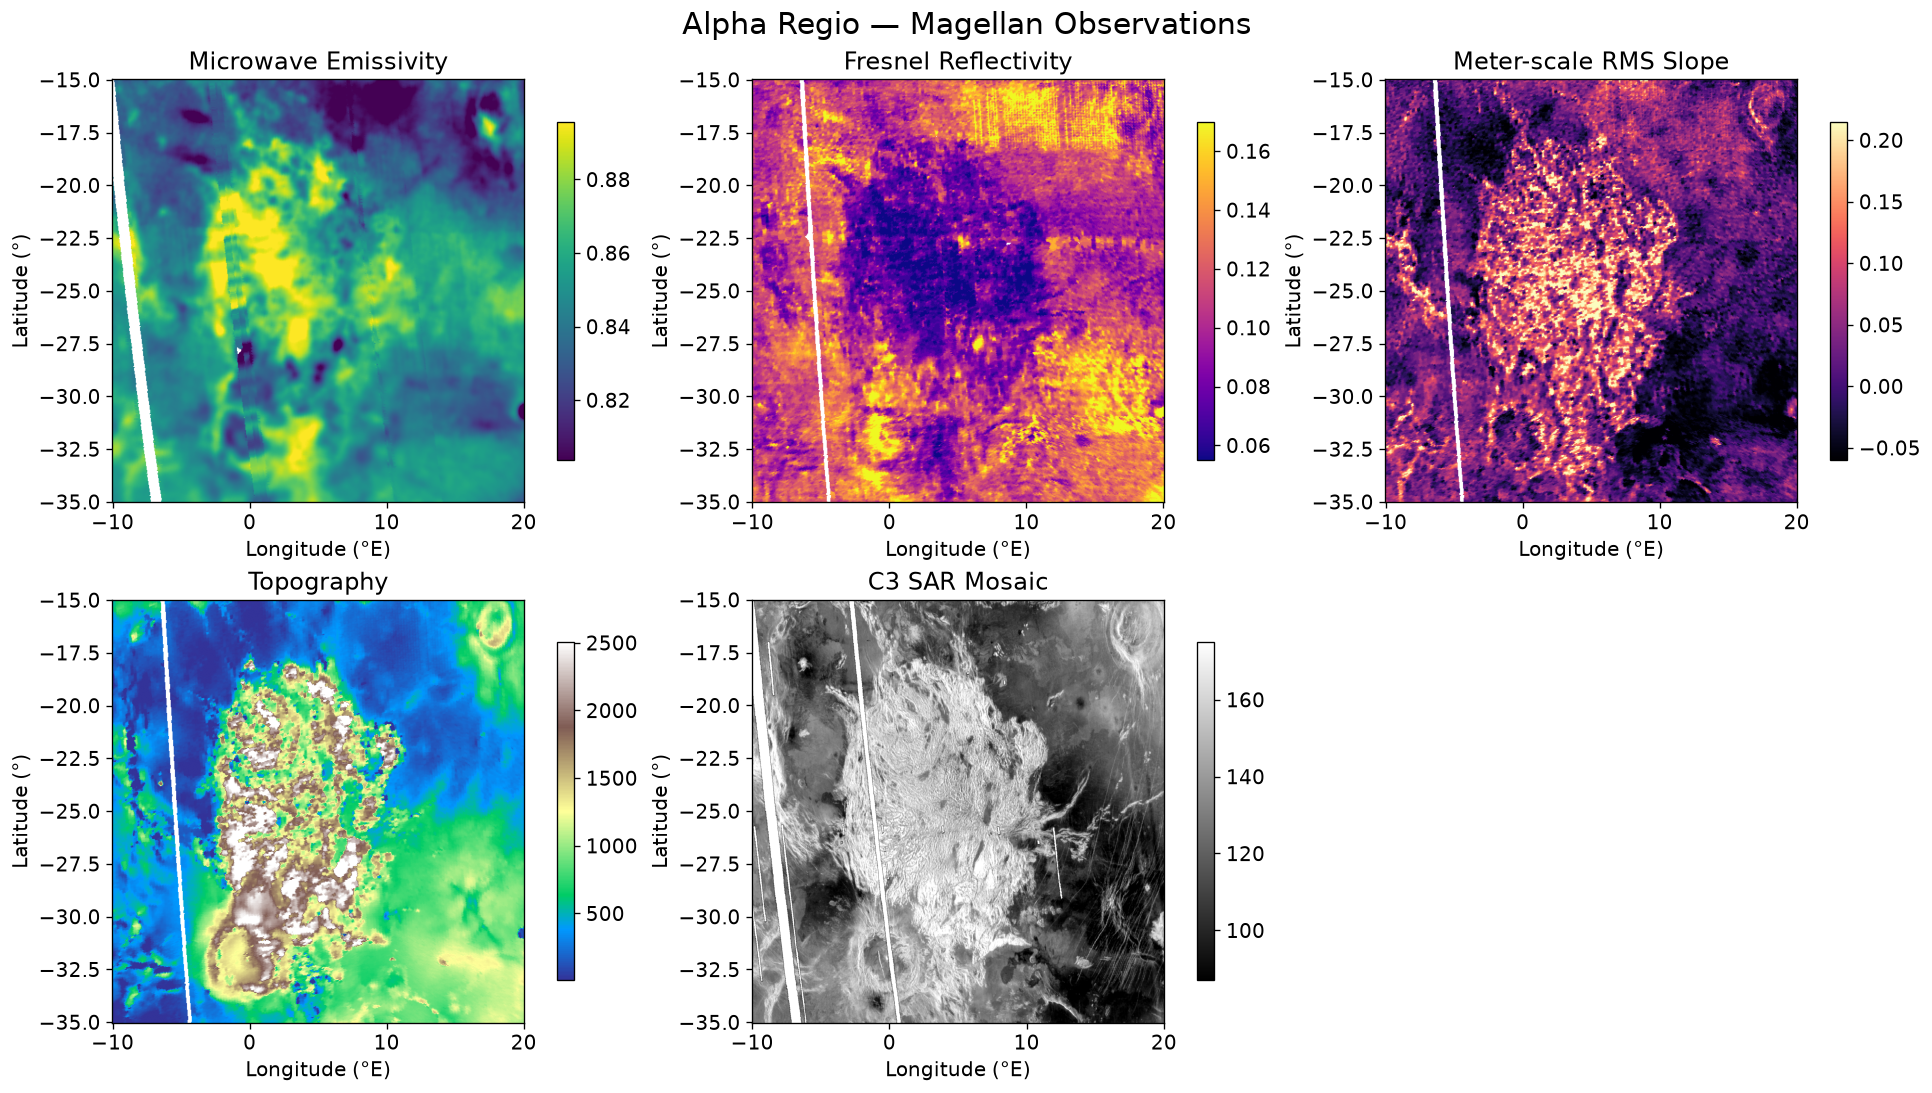

In [28]:
region_name = "Alpha_Regio"

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    constrained_layout=True
)

axes = axes.flatten()

for i, name in enumerate(datasets):

    data, extent = extract_region(
        name,
        region_name
    )

    values = data.compressed()

    if len(values) == 0:
        axes[i].set_title(f"{name}: No valid data")
        continue

    vmin, vmax = np.percentile(values, [2, 98])

    im = axes[i].imshow(
        data,
        extent=extent,
        origin="upper",
        cmap=cmaps[name],
        vmin=vmin,
        vmax=vmax,
        aspect="auto"
    )

    axes[i].set_title(titles[name])
    axes[i].set_xlabel("Longitude (°E)")
    axes[i].set_ylabel("Latitude (°)")

    plt.colorbar(
        im,
        ax=axes[i],
        shrink=0.8
    )

axes[-1].axis("off")

plt.suptitle(
    "Alpha Regio — Magellan Observations",
    fontsize=18
)

plt.show()

## Plot the five datasets for Themis Regio

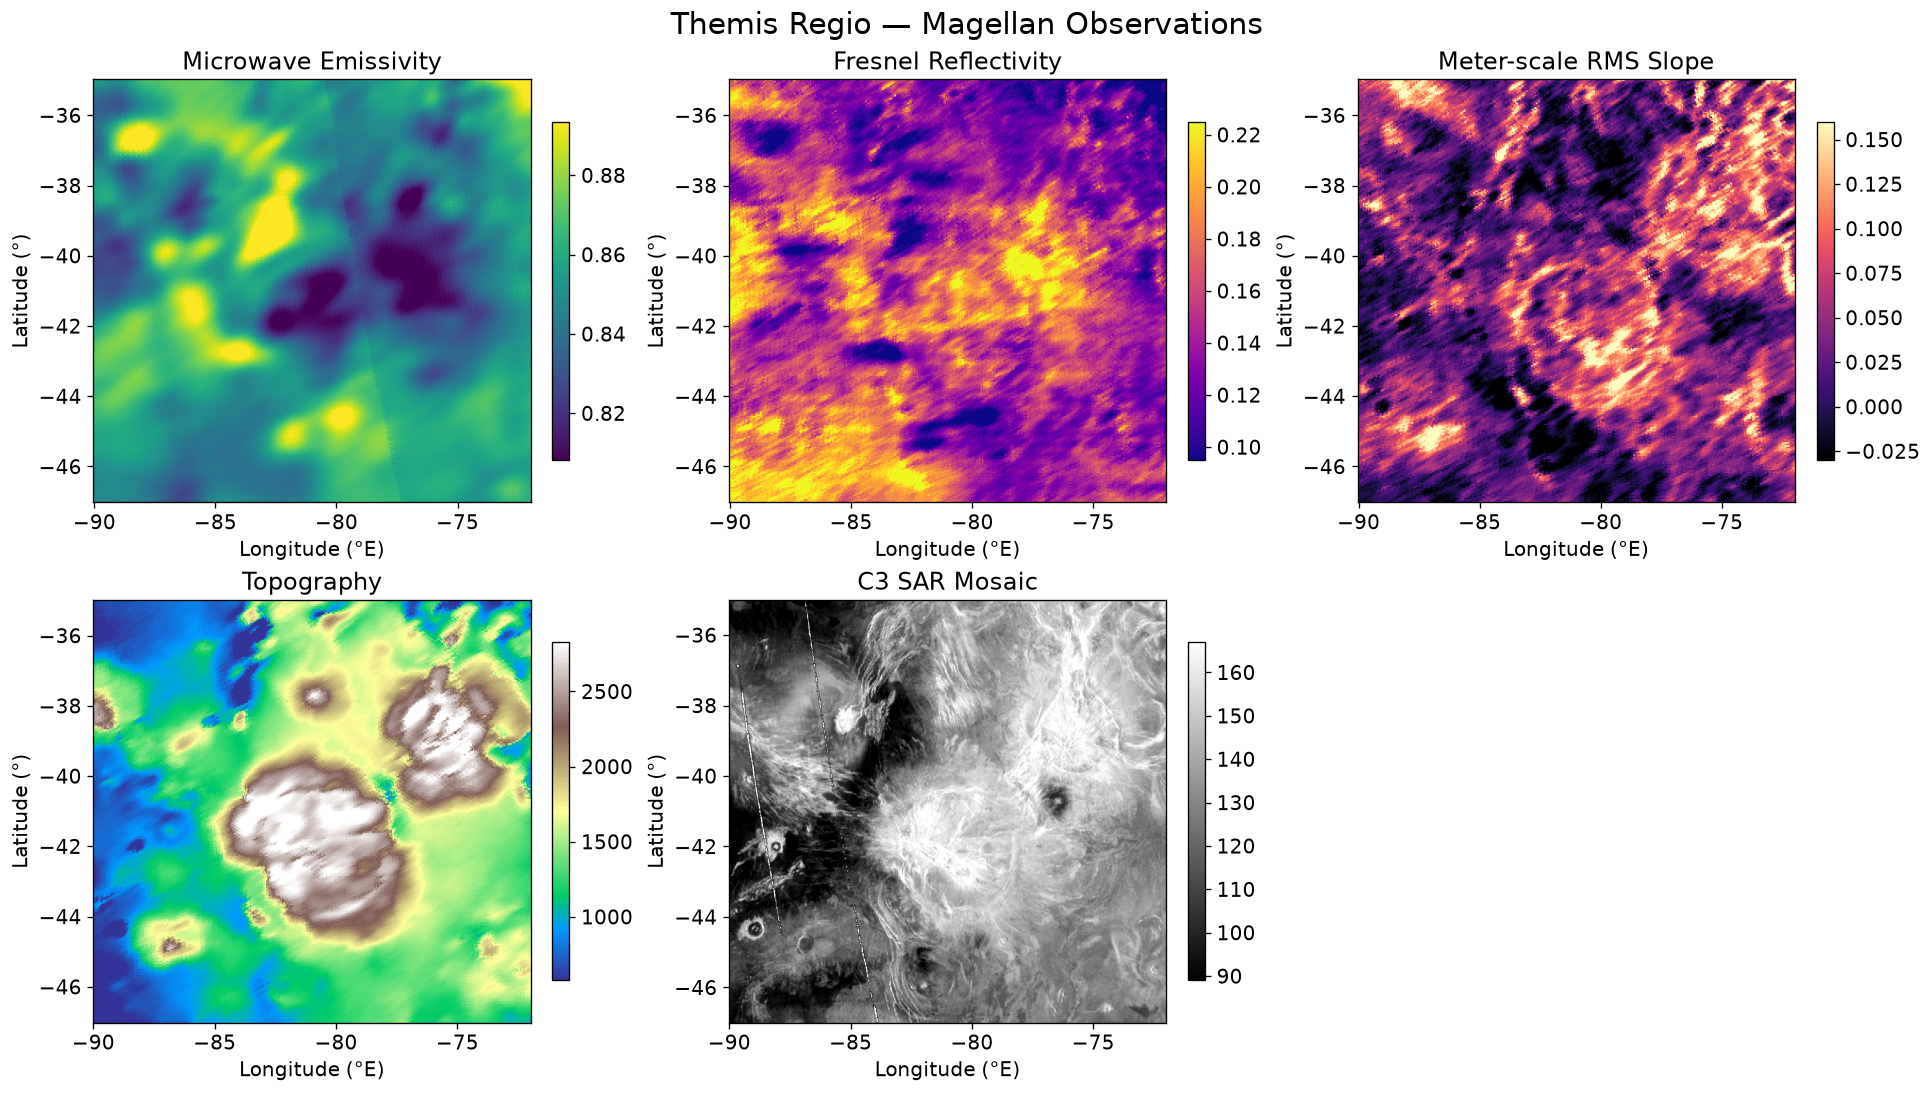

In [29]:
region_name = "Themis_Regio"

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    constrained_layout=True
)

axes = axes.flatten()

for i, name in enumerate(datasets):

    data, extent = extract_region(
        name,
        region_name
    )

    values = data.compressed()

    if len(values) == 0:
        axes[i].set_title(f"{name}: No valid data")
        continue

    vmin, vmax = np.percentile(values, [2, 98])

    im = axes[i].imshow(
        data,
        extent=extent,
        origin="upper",
        cmap=cmaps[name],
        vmin=vmin,
        vmax=vmax,
        aspect="auto"
    )

    axes[i].set_title(titles[name])
    axes[i].set_xlabel("Longitude (°E)")
    axes[i].set_ylabel("Latitude (°)")

    plt.colorbar(
        im,
        ax=axes[i],
        shrink=0.8
    )

axes[-1].axis("off")

plt.suptitle(
    "Themis Regio — Magellan Observations",
    fontsize=18
)

plt.show()

# EDA

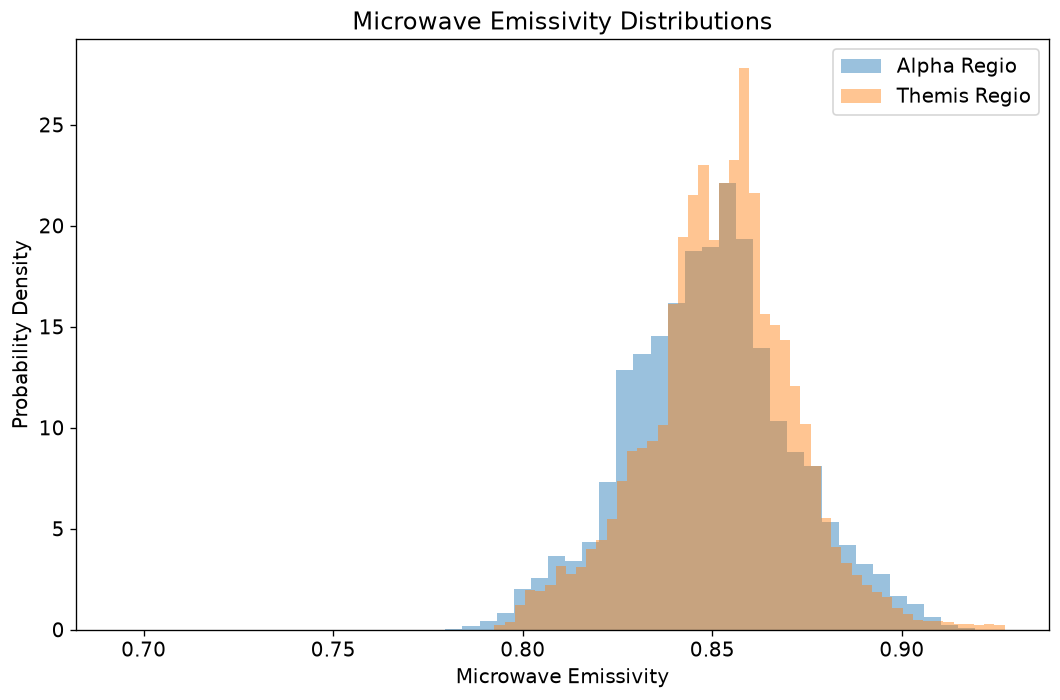

In [30]:
fig, ax = plt.subplots(figsize=(9, 6))

for region_name in REGIONS:

    data, _ = extract_region(
        "Emissivity",
        region_name
    )

    values = data.compressed()

    ax.hist(
        values,
        bins=50,
        density=True,
        alpha=0.45,
        label=region_name.replace("_", " ")
    )

ax.set_xlabel("Microwave Emissivity")
ax.set_ylabel("Probability Density")
ax.set_title("Microwave Emissivity Distributions")
ax.legend()

plt.tight_layout()
plt.show()

In [31]:
regional_stats = []

for region_name in REGIONS:

    for dataset_name in datasets:

        data, _ = extract_region(
            dataset_name,
            region_name
        )

        values = data.compressed()

        if len(values) == 0:
            continue

        regional_stats.append({
            "Region": region_name,
            "Dataset": dataset_name,
            "N_valid_pixels": len(values),
            "Mean": np.mean(values),
            "Std": np.std(values),
            "Median": np.median(values),
            "Min": np.min(values),
            "Max": np.max(values)
        })

df_regional_stats = pd.DataFrame(regional_stats)

display(df_regional_stats.round(4))

,Region,Dataset,N_valid_pixels,Mean,Std,Median,Min,Max
0,Alpha_Regio,Emissivity,304432,0.8494,0.0214,0.8496,0.6939,0.9194
1,Alpha_Regio,Reflectivity,308753,0.1097,0.0284,0.1100,0.0400,0.3600
2,Alpha_Regio,RMS_Slope,308805,0.0368,0.0672,0.0250,-0.0850,0.4550
3,Alpha_Regio,Topography,308807,787.1402,650.9413,664.0000,-2500.0000,5868.0000
4,Alpha_Regio,SAR,1571761,130.9193,23.6026,130.0000,1.0000,227.0000
5,Themis_Regio,Emissivity,112614,0.8522,0.0194,0.8531,0.7925,0.9271
6,Themis_Regio,Reflectivity,112614,0.1541,0.0335,0.1500,0.0600,0.4050
7,Themis_Regio,RMS_Slope,112614,0.0449,0.0483,0.0400,-0.0700,0.3350
8,Themis_Regio,Topography,112340,1518.5818,602.5488,1425.0000,-383.0000,3330.0000
9,Themis_Regio,SAR,586800,130.8690,20.9887,133.0000,6.0000,200.0000


In [32]:
names = [
    "Emissivity",
    "Reflectivity",
    "RMS_Slope",
    "Topography",
    "SAR"
]

with rasterio.open(FILES["Emissivity"]) as ref:

    for name in names:

        with rasterio.open(FILES[name]) as src:

            print(f"\n{name}")
            print("Same CRS:", src.crs == ref.crs)
            print("Same transform:", src.transform == ref.transform)
            print(
                "Same dimensions:",
                (src.width, src.height) ==
                (ref.width, ref.height)
            )


Emissivity
Same CRS: True
Same transform: True
Same dimensions: True

Reflectivity
Same CRS: True
Same transform: True
Same dimensions: True

RMS_Slope
Same CRS: True
Same transform: True
Same dimensions: True

Topography
Same CRS: True
Same transform: False
Same dimensions: False

SAR
Same CRS: True
Same transform: False
Same dimensions: False
